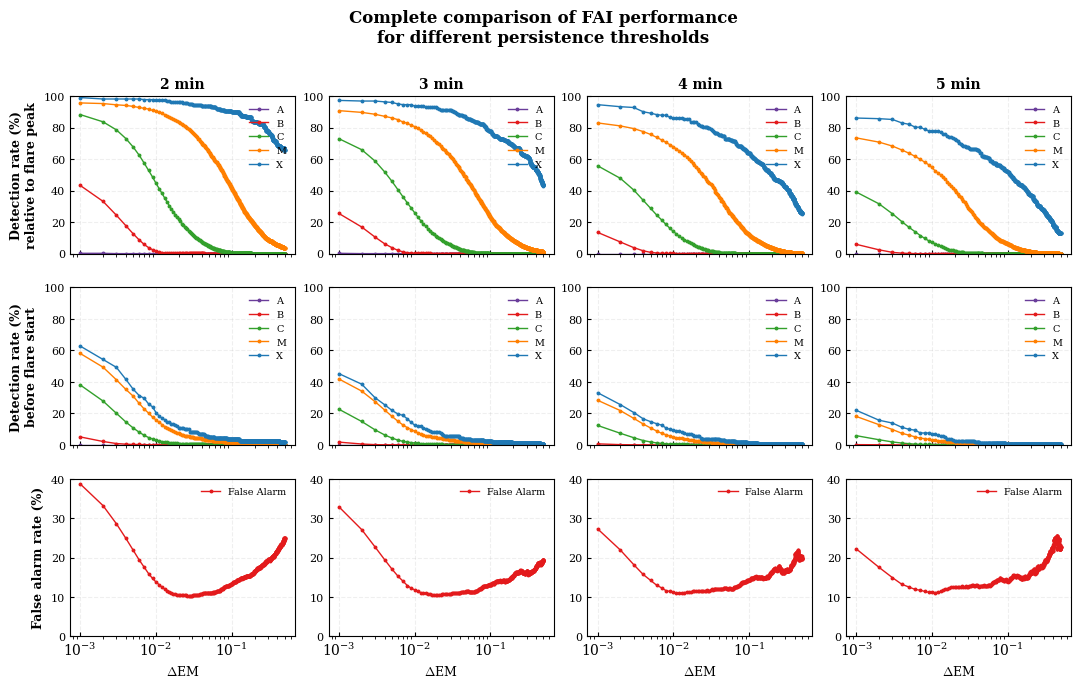

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

# ==========================================================
# ESTILO TIPO LATEX (CLAVE 🔥)
# ==========================================================
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "text.usetex": False,   # pon True si tienes LaTeX instalado
    "mathtext.fontset": "cm",

    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 10,
    "ytick.labelsize": 8,
    "legend.fontsize": 7,

    "axes.linewidth": 0.8,
})

files = {
    "2 min": "FAI_global_summary_filteredend_nooverlap_2min_500.csv",
    "3 min": "FAI_global_summary_filteredend_nooverlap_3min_500.csv",
    "4 min": "FAI_global_summary_filteredend_nooverlap_4min_500.csv",
    "5 min": "FAI_global_summary_filteredend_nooverlap_5min_500.csv",
}

flare_classes = ['A', 'B', 'C', 'M', 'X']

colors = {
    'A': '#6a3d9a',
    'B': '#e31a1c',
    'C': '#33a02c',
    'M': '#ff7f00',
    'X': '#1f78b4'
}

# 👇 TAMAÑO MÁS COMPACTO (CLAVE)
fig, axes = plt.subplots(3, 4, figsize=(11, 7), sharex='col')

for col, (duration, file) in enumerate(files.items()):

    df = pd.read_csv(file)
    df["ΔEM"] = pd.to_numeric(df["ΔEM"])
    df = df.sort_values("ΔEM")

    # ======================================================
    # ROW 1
    # ======================================================
    ax = axes[0, col]

    for cl in flare_classes:
        ax.plot(df["ΔEM"], df[f"{cl}_Peak"],
                marker='o',
                markersize=1.8,
                linewidth=1.0,
                color=colors[cl],
                label=cl)

    ax.set_xscale("log")
    ax.set_ylim(0, 100)

    # 👇 TÍTULO DOBLE COMO PAPER
    ax.set_title(f"{duration}", fontweight='bold')

    if col == 0:
        ax.set_ylabel("Detection rate (%)\nrelative to flare peak", fontweight='bold')

    ax.legend(frameon=False, loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.2)
    ax.tick_params(direction='in', length=3)

    # ======================================================
    # ROW 2
    # ======================================================
    ax = axes[1, col]

    for cl in flare_classes:
        ax.plot(df["ΔEM"], df[f"{cl}_Start"],
                marker='o',
                markersize=1.8,
                linewidth=1.0,
                color=colors[cl],
                label=cl)

    ax.set_xscale("log")
    ax.set_ylim(0, 100)


    if col == 0:
        ax.set_ylabel("Detection rate (%)\nbefore flare start", fontweight='bold')

    ax.legend(frameon=False, loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.2)
    ax.tick_params(direction='in', length=3)

    # ======================================================
    # ROW 3
    # ======================================================
    ax = axes[2, col]

    ax.plot(df["ΔEM"], df["False Alarm (%)"],
            color="#e31a1c",
            marker='o',
            markersize=1.8,
            linewidth=1.0,
            label="False Alarm")

    ax.set_xscale("log")
    ax.set_ylim(0, 40)


    if col == 0:
        ax.set_ylabel("False alarm rate (%)", fontweight='bold')

    ax.set_xlabel(r"$\Delta$EM")

    ax.legend(frameon=False, loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.2)
    ax.tick_params(direction='in', length=3)

# ==========================================================
# 🔥 ESPACIADO TIPO PAPER
# ==========================================================
plt.subplots_adjust(
    left=0.07,
    right=0.98,
    bottom=0.08,
    top=0.9,   # 🔥 MÁS espacio para el título
    wspace=0.15,
    hspace=0
)

#paneles más o menos cuadrados
for row in axes:
    for ax in row:
        ax.set_box_aspect(0.7)

# 👇 TÍTULO GLOBAL MÁS PEQUEÑO
fig.suptitle(
    "Complete comparison of FAI performance\nfor different persistence thresholds",
    fontsize=12,
    fontweight='bold',
    y=1.0   # 🔥 baja el título (antes estaba muy arriba o muy pegado)
)

plt.savefig("Persistence_Comparison_2_3_4_5min.pdf", dpi=600, bbox_inches='tight')
plt.savefig("Persistence_Comparison_2_3_4_5min.png", dpi=600, bbox_inches='tight')
plt.show()